In [ ]:
# @title Ingrese datos
nombre_estudiante = "Daniel Bermudez Chacon" # @param {"type":"string"}
carnet = 1000115472 # @param {"type":"integer"}


## 1) Descripción del problema [1 pts]
Una empresa debe (a) administrar tareas técnicas según su prioridad, atendiendo siempre la más urgente, y (b) conectar seis dispositivos usando la menor cantidad total de cable.



## 2) Requerimientos [2 pts]
**Funcionales**
-  Construir un Max-Heap a partir de la lista de tareas (max-heapify y build-max-heap)
-  Mostrar el arreglo inicial, el heap resultante y su representación en árbol
-  Extraer la tarea de mayor prioridad (extract max) y mostrar el heap tras cada extracción
-  Insertar una nueva tarea manteniendo la propiedad de Max-Heap
-  Graficar la posición de los seis dispositivos
-  Calcular la distancia entre cada pareja de dispositivos
-  Obtener el MST con Kruskal (Union-Find) y mostrar aristas y costo total
**No funcionales**
- No usar heapq ni funciones de MST de librerías
- Todo el desarrollo en un único notebook ejecutable de principio a fin
- Eficiencia: operaciones del heap en O(log n) y Kruskal en O(E log E)


## 3) Historias de usuario [2 pts]
**1.** Como técnico de soporte, quiero ver primero la tarea más urgente para atender los problemas críticos a tiempo.
-  al extraer, siempre sale la tarea de mayor prioridad y la extracción del heap sigue siendo un Max-Heap

**2.** Como coordinador, quiero agregar tareas nuevas en cualquier momento para que las emergencias entren a la cola
- la tarea queda en la raíz y el heap conserva su propiedad

**3.** Como ingeniero de redes, quiero ver la posición de los dispositivos para entender la distribución física
-  la gráfica muestra los 6 puntos con su ID y nombre
**4.** Como jefe de infraestructura, quiero conectar todos los dispositivos con la menor cantidad de cable para reducir costos
-  el resultado tiene 5 aristas que conecta los 6 dispositivos sin ciclos

**5.** Como estudiante evaluado, quiero pruebas automáticas para verificar que mi implementación es correcta.
- todos los asserts pasan sin problemas

## 4) Diagramas de flujo **[5 pts]**
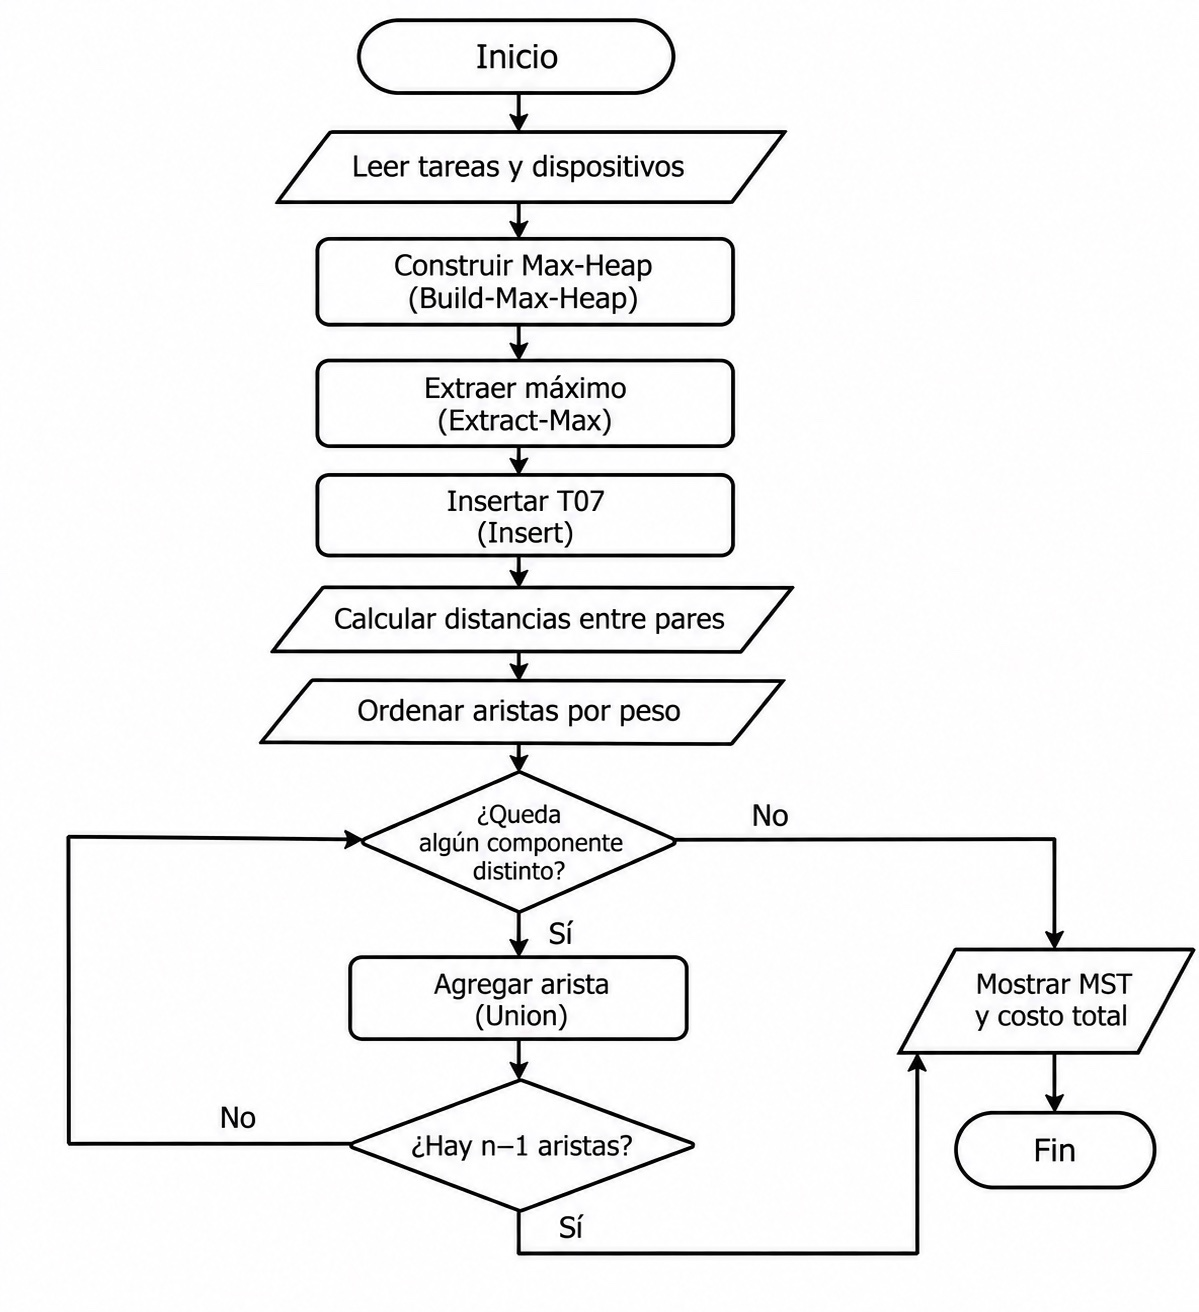

Se construye el Max-Heap con las tareas, se extraen las dos de mayor prioridad y se inserta T07 y Luego se calculan las distancias entre dispositivos, se ordenan las aristas y Kruskal agrega cada una solo si no forma ciclo hasta tener 5 aristas al final se muestra el MST y su costo total

## 5) Análisis de complejidad [15 pts]
Justificación

Max Heapify: baja un nodo hasta ubicarlo correctamente. Como la altura del heap es , su complejidad es O(log n)

Build Max Heap: aplica Heapify a todos los nodos. Aunque se repite varias veces, el costo total es O(n)

Extract Max: reemplaza la raíz y reorganiza el heap, por lo que cuesta O(log n)

Insert: el nuevo elemento sube hasta su posición correcta, con costo O(log n)

Kruskal: debe ordenar las aristas y unir conjuntos; su complejidad dominante es O(E log E)
Función T(n)
Insert:  donde  es el número de niveles que sube el elemento.
Max Heapify: , entonces
Build Max Heap: suma el costo de todos los Heapify y resulta en O(n)

**Mejor y peor caso**
Mejor caso: el elemento insertado ya está en la posición correcta, costo O(1).
Peor caso: el elemento debe subir hasta la raíz, costo O(log n)



## 6) Código funcional [15 pts]

Arreglo inicial: ['T01(6)', 'T02(10)', 'T03(4)', 'T04(8)', 'T05(3)', 'T06(7)']
Max-Heap resultante: ['T02(10)', 'T04(8)', 'T06(7)', 'T01(6)', 'T05(3)', 'T03(4)']
             T02(10)  
      T04(8)   T06(7)
T01(6)   T05(3)   T03(4)


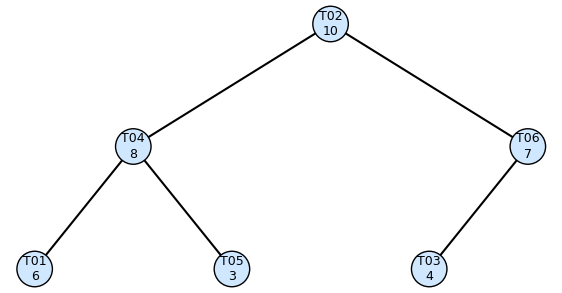


Tarea procesada: ('T02', 'Reparar sensor', 10)
Heap resultante: ['T04(8)', 'T01(6)', 'T06(7)', 'T03(4)', 'T05(3)']

Tarea procesada: ('T04', 'Revisar cámara', 8)
Heap resultante: ['T06(7)', 'T01(6)', 'T05(3)', 'T03(4)']

Heap después de insertar T07: ['T07(12)', 'T06(7)', 'T05(3)', 'T03(4)', 'T01(6)']
             T07(12)  
      T06(7)   T05(3)
T03(4)   T01(6)


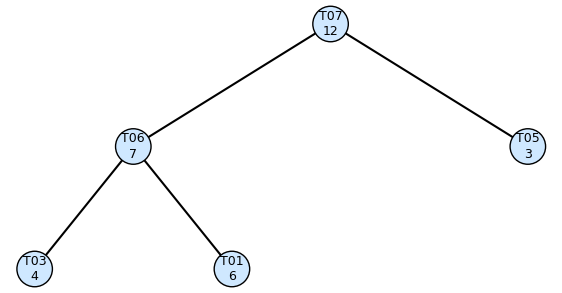


Distancias entre pares:
  A-B: 5.099
  A-C: 5.385
  A-D: 10.000
  A-E: 11.045
  A-F: 13.928
  B-C: 5.000
  B-D: 5.831
  B-E: 6.000
  B-F: 8.944
  C-D: 6.083
  C-E: 9.849
  C-F: 11.000
  D-E: 5.831
  D-F: 5.099
  E-F: 4.472


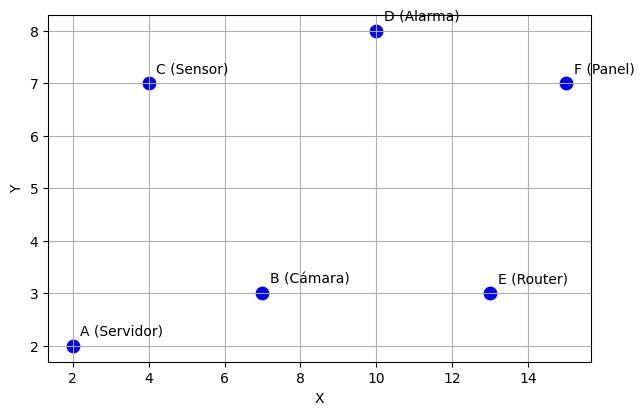


Kruskal:
  Se agrega E-F: 4.472
  Se agrega B-C: 5.000
  Se agrega A-B: 5.099
  Se agrega D-F: 5.099
  Se descarta A-C: 5.385 (forma ciclo)
  Se agrega B-D: 5.831
Costo total mínimo de cable: 25.501


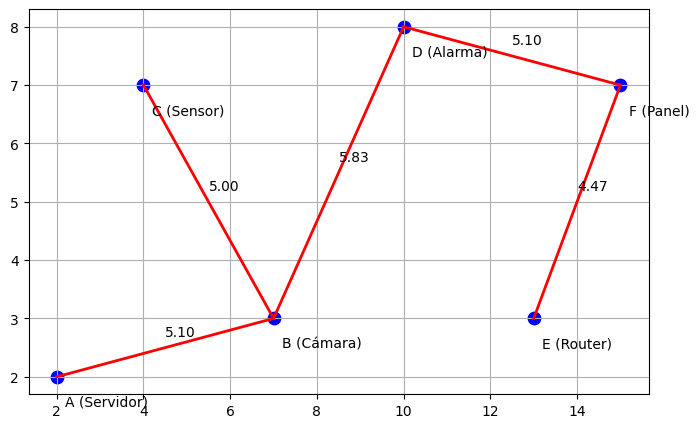

In [1]:

import math
import matplotlib.pyplot as plt
tareas=[("T01","Configurar servidor",6),("T02","Reparar sensor",10),("T03","Actualizar software",4),("T04","Revisar cámara",8),("T05","Generar respaldo",3),("T06","Configurar alarma",7)]
def max_heapify(A,n,i):
   mayor,l,r=i,2*i+1,2*i+2
   if l<n and A[l][2]>A[mayor][2]: mayor=l
   if r<n and A[r][2]>A[mayor][2]: mayor=r
   if mayor!=i:
       A[i],A[mayor]=A[mayor],A[i]
       max_heapify(A,n,mayor)
def build_max_heap(A):
   for i in range(len(A)//2-1,-1,-1):
       max_heapify(A,len(A),i)
def ver(A):
   return [f"{t[0]}({t[2]})" for t in A]
def imprimir_arbol(A):
   nivel,i=0,0
   altura=int(math.log2(len(A)))+1 if A else 0
   while i<len(A):
       print("      "*(altura-nivel-1)+"   ".join(ver(A[i:i+2**nivel])).center(10))
       i+=2**nivel
       nivel+=1
def dibujar_arbol(A):
   fig,ax=plt.subplots(figsize=(7,3.5))
   ax.axis("off")
   pos={}
   for i in range(len(A)):
       nivel=int(math.log2(i+1))
       k=i-(2**nivel-1)
       pos[i]=((k+0.5)/2**nivel*10,-nivel*2)
   for i in range(1,len(A)):
       p=(i-1)//2
       ax.plot([pos[p][0],pos[i][0]],[pos[p][1],pos[i][1]],"k-",zorder=1)
   for i,t in enumerate(A):
       ax.text(pos[i][0],pos[i][1],f"{t[0]}\n{t[2]}",ha="center",va="center",fontsize=9,bbox=dict(boxstyle="circle",fc="#cfe8ff"),zorder=2)
   plt.show()
heap=tareas.copy()
print("Arreglo inicial:",ver(heap))
build_max_heap(heap)
print("Max-Heap resultante:",ver(heap))
imprimir_arbol(heap)
dibujar_arbol(heap)
def extract_max(A):
   mx=A[0]
   A[0]=A[-1]
   A.pop()
   if A: max_heapify(A,len(A),0)
   return mx
def insert(A,t):
   A.append(t)
   i=len(A)-1
   while i>0 and A[(i-1)//2][2]<A[i][2]:
       A[i],A[(i-1)//2]=A[(i-1)//2],A[i]
       i=(i-1)//2
for _ in range(2):
   print("\nTarea procesada:",extract_max(heap))
   print("Heap resultante:",ver(heap))
insert(heap,("T07","Falla en sistema contra incendios",12))
print("\nHeap después de insertar T07:",ver(heap))
imprimir_arbol(heap)
dibujar_arbol(heap)
disp={"A":(2,2),"B":(7,3),"C":(4,7),"D":(10,8),"E":(13,3),"F":(15,7)}
nombres={"A":"Servidor","B":"Cámara","C":"Sensor","D":"Alarma","E":"Router","F":"Panel"}
def distancia(p,q):
   return math.sqrt((q[0]-p[0])**2+(q[1]-p[1])**2)
aristas=[]
ids=list(disp)
print("\nDistancias entre pares:")
for i in range(len(ids)):
   for j in range(i+1,len(ids)):
       d=distancia(disp[ids[i]],disp[ids[j]])
       aristas.append((d,ids[i],ids[j]))
       print(f"  {ids[i]}-{ids[j]}: {d:.3f}")
plt.figure(figsize=(7,4.5))
for k,(x,y) in disp.items():
   plt.scatter(x,y,c="blue",s=80)
   plt.text(x+0.2,y+0.2,f"{k} ({nombres[k]})")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()
padre={k:k for k in disp}
def find(x):
   while padre[x]!=x:
       padre[x]=padre[padre[x]]
       x=padre[x]
   return x
def union(a,b):
   ra,rb=find(a),find(b)
   if ra==rb: return False
   padre[rb]=ra
   return True
def ordenar(lista):
   L=lista.copy()
   for i in range(1,len(L)):
       k,j=L[i],i-1
       while j>=0 and L[j][0]>k[0]:
           L[j+1]=L[j]
           j-=1
       L[j+1]=k
   return L
def kruskal(aristas,vertices):
   global padre
   padre={k:k for k in vertices}
   mst,total=[],0
   for d,a,b in ordenar(aristas):
       if union(a,b):
           mst.append((a,b,d))
           total+=d
           print(f"  Se agrega {a}-{b}: {d:.3f}")
       else:
           print(f"  Se descarta {a}-{b}: {d:.3f} (forma ciclo)")
       if len(mst)==len(vertices)-1: break
   return mst,total
print("\nKruskal:")
mst,total=kruskal(aristas,list(disp))
print(f"Costo total mínimo de cable: {total:.3f}")
plt.figure(figsize=(8,5))
for a,b,d in mst:
   (x1,y1),(x2,y2)=disp[a],disp[b]
   plt.plot([x1,x2],[y1,y2],"r-",lw=2)
   plt.text((x1+x2)/2,(y1+y2)/2+0.2,f"{d:.2f}")
for k,(x,y) in disp.items():
   plt.scatter(x,y,c="blue",s=80)
   plt.text(x+0.2,y-0.5,f"{k} ({nombres[k]})")
plt.grid(True)
plt.show()

## 7) Tests aplicados [15 pts]

In [ ]:
def es_max_heap(A):
    return all(A[(i-1)//2][2] >= A[i][2] for i in range(1, len(A)))

# Heap inicial
h = tareas.copy(); build_max_heap(h)
assert es_max_heap(h)
assert [t[0] for t in h] == ["T02","T04","T06","T01","T05","T03"]

# Extracciones
h2 = h.copy()
assert extract_max(h2)[0] == "T02" and es_max_heap(h2)
assert extract_max(h2)[0] == "T04" and es_max_heap(h2)


insert(h2, ("T07","Falla en sistema contra incendios",12))
assert h2[0][0] == "T07" and es_max_heap(h2) and len(h2) == 5

# Distancias
assert distancia((0,0),(3,4)) == 5
assert abs(distancia(disp["B"], disp["C"]) - 5.0) < 1e-9
assert abs(distancia(disp["A"], disp["B"]) - math.sqrt(26)) < 1e-9

# Kruskal
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    mst_t, total_t = kruskal(aristas, list(disp))
assert len(mst_t) == 5
assert abs(total_t - 25.501) < 0.001
assert len({find(k) for k in disp}) == 1   # todos conectados

# Casos borde del heap
vacio = []; build_max_heap(vacio); assert vacio == []
uno = [("X","u",1)]; assert extract_max(uno)[0] == "X" and uno == []
print("Todos los tests pasaron ✔")